<a href="https://colab.research.google.com/github/oabdelhalim8/ML---4/blob/main/ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys

assert sys.version_info >= (3, 10)

In [2]:
from packaging.version import Version
import sklearn

assert Version(sklearn.__version__) >= Version("1.6.1")

In [3]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [4]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

iris = load_iris(as_frame=True)
X_iris = iris.data[["petal length (cm)", "petal width (cm)"]].values
y_iris = iris.target

tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X_iris, y_iris)

DecisionTreeClassifier(max_depth=2, random_state=42)

In [5]:
from sklearn.tree import export_graphviz

export_graphviz(
        tree_clf,
        out_file="my_iris_tree.dot",  # path differs in the book
        feature_names=["petal length (cm)", "petal width (cm)"],
        class_names=iris.target_names,
        rounded=True,
        filled=True
    )

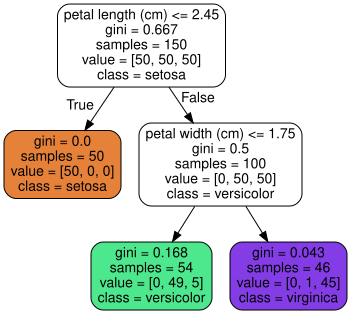

In [6]:
from graphviz import Source

Source.from_file("my_iris_tree.dot")  # path differs in the book

In [7]:
# extra code
!dot -Tpng "my_iris_tree.dot" -o "my_iris_tree.png"

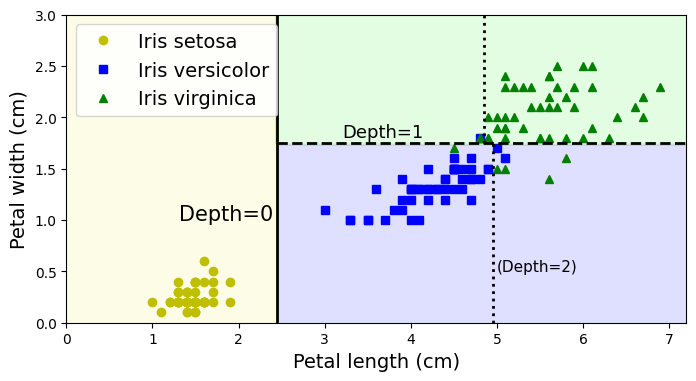

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# extra code – just formatting details
from matplotlib.colors import ListedColormap
custom_cmap = ListedColormap(['#fafab0', '#9898ff', '#a0faa0'])
plt.figure(figsize=(8, 4))

lengths, widths = np.meshgrid(np.linspace(0, 7.2, 100), np.linspace(0, 3, 100))
X_iris_all = np.c_[lengths.ravel(), widths.ravel()]
y_pred = tree_clf.predict(X_iris_all).reshape(lengths.shape)
plt.contourf(lengths, widths, y_pred, alpha=0.3, cmap=custom_cmap)
for idx, (name, style) in enumerate(zip(iris.target_names, ("yo", "bs", "g^"))):
    plt.plot(X_iris[:, 0][y_iris == idx], X_iris[:, 1][y_iris == idx],
             style, label=f"Iris {name}")

# extra code – this section beautifies Figure 5–2
tree_clf_deeper = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf_deeper.fit(X_iris, y_iris)
th0, th1, th2a, th2b = tree_clf_deeper.tree_.threshold[[0, 2, 3, 6]]
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.plot([th0, th0], [0, 3], "k-", linewidth=2)
plt.plot([th0, 7.2], [th1, th1], "k--", linewidth=2)
plt.plot([th2a, th2a], [0, th1], "k:", linewidth=2)
plt.plot([th2b, th2b], [th1, 3], "k:", linewidth=2)
plt.text(th0 - 0.05, 1.0, "Depth=0", horizontalalignment="right", fontsize=15)
plt.text(3.2, th1 + 0.02, "Depth=1", verticalalignment="bottom", fontsize=13)
plt.text(th2a + 0.05, 0.5, "(Depth=2)", fontsize=11)
plt.axis([0, 7.2, 0, 3])
plt.legend()

plt.show()

In [9]:
tree_clf.tree_

In [13]:
help(tree_clf.tree_)

Help on Tree object:

class Tree(builtins.object)
 |  Array-based representation of a binary decision tree.
 |
 |  The binary tree is represented as a number of parallel arrays. The i-th
 |  element of each array holds information about the node `i`. Node 0 is the
 |  tree's root. You can find a detailed description of all arrays in
 |  `_tree.pxd`. NOTE: Some of the arrays only apply to either leaves or split
 |  nodes, resp. In this case the values of nodes of the other type are
 |  arbitrary!
 |
 |  Attributes
 |  ----------
 |  node_count : intp_t
 |      The number of nodes (internal nodes + leaves) in the tree.
 |
 |  capacity : intp_t
 |      The current capacity (i.e., size) of the arrays, which is at least as
 |      great as `node_count`.
 |
 |  max_depth : intp_t
 |      The depth of the tree, i.e. the maximum depth of its leaves.
 |
 |  children_left : array of intp_t, shape [node_count]
 |      children_left[i] holds the node id of the left child of node i.
 |      For lea

In [12]:
#help(sklearn.tree._tree.Tree)

In [14]:
tree_clf.predict_proba([[5, 1.5]]).round(3)

array([[0.   , 0.907, 0.093]])

In [15]:
tree_clf.predict([[5, 1.5]])

array([1])

In [16]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=150, noise=0.2, random_state=42)

tree_clf1 = DecisionTreeClassifier(random_state=42)
tree_clf2 = DecisionTreeClassifier(min_samples_leaf=5, random_state=42)
tree_clf1.fit(X_moons, y_moons)
tree_clf2.fit(X_moons, y_moons)

DecisionTreeClassifier(min_samples_leaf=5, random_state=42)

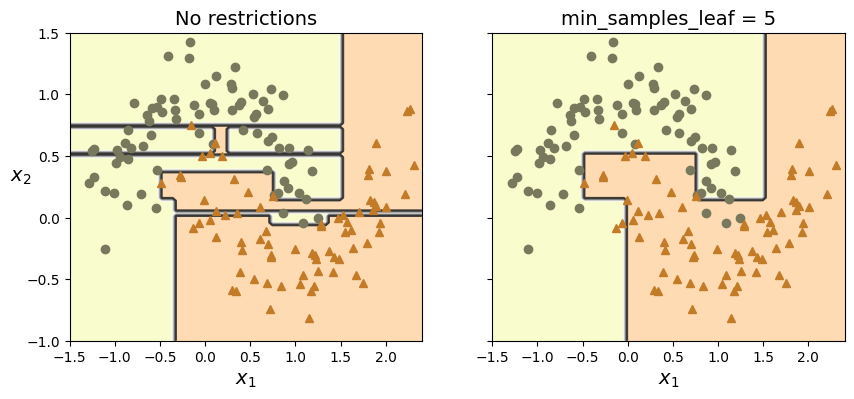

In [17]:
# extra code – this cell generates Figure 5–3

def plot_decision_boundary(clf, X, y, axes, cmap):
    x1, x2 = np.meshgrid(np.linspace(axes[0], axes[1], 100),
                         np.linspace(axes[2], axes[3], 100))
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)

    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=cmap)
    plt.contour(x1, x2, y_pred, cmap="Greys", alpha=0.8)
    colors = {"Wistia": ["#78785c", "#c47b27"], "Pastel1": ["red", "blue"]}
    markers = ("o", "^")
    for idx in (0, 1):
        plt.plot(X[:, 0][y == idx], X[:, 1][y == idx],
                 color=colors[cmap][idx], marker=markers[idx], linestyle="none")
    plt.axis(axes)
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$", rotation=0)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(tree_clf1, X_moons, y_moons,
                       axes=[-1.5, 2.4, -1, 1.5], cmap="Wistia")
plt.title("No restrictions")
plt.sca(axes[1])
plot_decision_boundary(tree_clf2, X_moons, y_moons,
                       axes=[-1.5, 2.4, -1, 1.5], cmap="Wistia")
plt.title(f"min_samples_leaf = {tree_clf2.min_samples_leaf}")
plt.ylabel("")

plt.show()

In [18]:
X_moons_test, y_moons_test = make_moons(n_samples=1000, noise=0.2,
                                        random_state=43)
tree_clf1.score(X_moons_test, y_moons_test)

0.898

In [19]:
tree_clf2.score(X_moons_test, y_moons_test)

0.92

In [21]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(seed=42)
X_quad = rng.random((200, 1)) - 0.5  # a single random input feature
y_quad = X_quad ** 2 + 0.025 * rng.standard_normal((200, 1))

tree_reg = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg.fit(X_quad, y_quad)

DecisionTreeRegressor(max_depth=2, random_state=42)

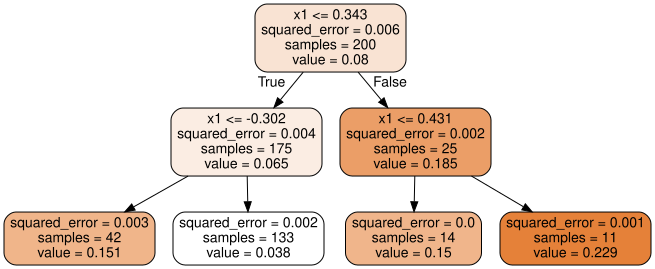

In [22]:
# extra code – we've already seen how to use export_graphviz()
export_graphviz(
    tree_reg,
    out_file="my_regression_tree.dot",
    feature_names=["x1"],
    rounded=True,
    filled=True
)
Source.from_file("my_regression_tree.dot")

In [23]:
tree_reg2 = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_reg2.fit(X_quad, y_quad)

DecisionTreeRegressor(max_depth=3, random_state=42)

In [24]:
tree_reg.tree_.threshold

array([ 0.34304063, -0.30182856, -2.        , -2.        ,  0.43140428,
       -2.        , -2.        ])

In [25]:
tree_reg2.tree_.threshold

array([ 0.34304063, -0.30182856, -0.41395289, -2.        , -2.        ,
        0.21817657, -2.        , -2.        ,  0.43140428,  0.39480372,
       -2.        , -2.        ,  0.46470371, -2.        , -2.        ])

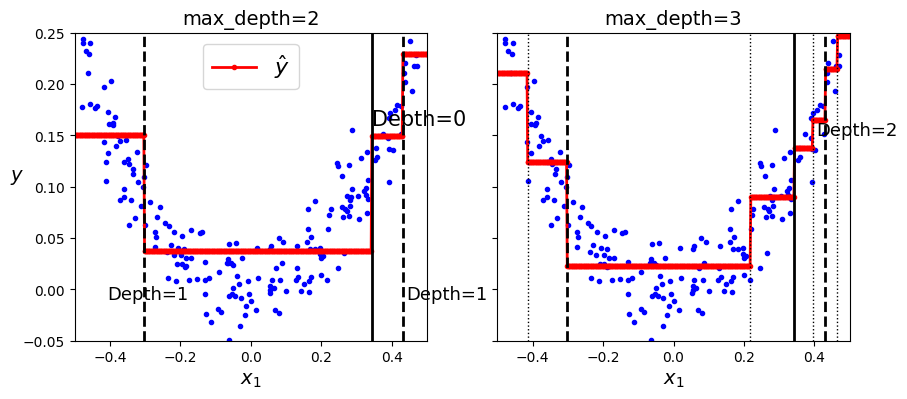

In [26]:
# extra code – this cell generates Figure 5–5

def plot_regression_predictions(tree_reg, X, y, axes=[-0.5, 0.5, -0.05, 0.25]):
    x1 = np.linspace(axes[0], axes[1], 500).reshape(-1, 1)
    y_pred = tree_reg.predict(x1)
    plt.axis(axes)
    plt.xlabel("$x_1$")
    plt.plot(X, y, "b.")
    plt.plot(x1, y_pred, "r.-", linewidth=2, label=r"$\hat{y}$")

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_regression_predictions(tree_reg, X_quad, y_quad)

th0, th1a, th1b = tree_reg.tree_.threshold[[0, 1, 4]]
for split, style in ((th0, "k-"), (th1a, "k--"), (th1b, "k--")):
    plt.plot([split, split], [-0.05, 0.25], style, linewidth=2)
plt.text(th0, 0.16, "Depth=0", fontsize=15)
plt.text(th1a + 0.01, -0.01, "Depth=1", horizontalalignment="center", fontsize=13)
plt.text(th1b + 0.01, -0.01, "Depth=1", fontsize=13)
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper center", fontsize=16)
plt.title("max_depth=2")

plt.sca(axes[1])
th2s = tree_reg2.tree_.threshold[[2, 5, 9, 12]]
plot_regression_predictions(tree_reg2, X_quad, y_quad)
for split, style in ((th0, "k-"), (th1a, "k--"), (th1b, "k--")):
    plt.plot([split, split], [-0.05, 0.25], style, linewidth=2)
for split in th2s:
    plt.plot([split, split], [-0.05, 0.25], "k:", linewidth=1)
plt.text(th2s[2] + 0.01, 0.15, "Depth=2", fontsize=13)
plt.title("max_depth=3")

plt.show()

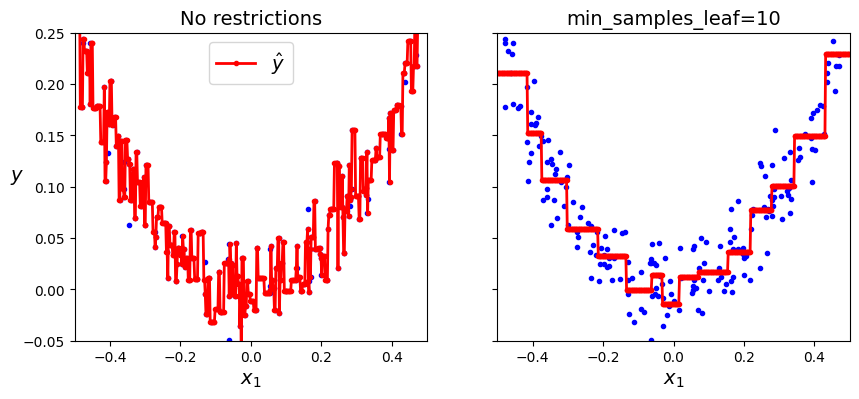

In [27]:
# extra code – this cell generates Figure 5–6

tree_reg1 = DecisionTreeRegressor(random_state=42)
tree_reg2 = DecisionTreeRegressor(random_state=42, min_samples_leaf=10)
tree_reg1.fit(X_quad, y_quad)
tree_reg2.fit(X_quad, y_quad)

x1 = np.linspace(-0.5, 0.5, 500).reshape(-1, 1)
y_pred1 = tree_reg1.predict(x1)
y_pred2 = tree_reg2.predict(x1)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)

plt.sca(axes[0])
plt.plot(X_quad, y_quad, "b.")
plt.plot(x1, y_pred1, "r.-", linewidth=2, label=r"$\hat{y}$")
plt.axis([-0.5, 0.5, -0.05, 0.25])
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper center")
plt.title("No restrictions")

plt.sca(axes[1])
plt.plot(X_quad, y_quad, "b.")
plt.plot(x1, y_pred2, "r.-", linewidth=2, label=r"$\hat{y}$")
plt.axis([-0.5, 0.5, -0.05, 0.25])
plt.xlabel("$x_1$")
plt.title(f"min_samples_leaf={tree_reg2.min_samples_leaf}")

plt.show()

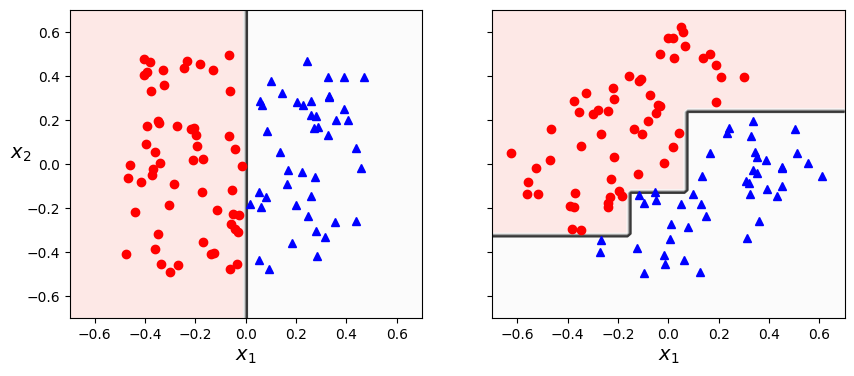

In [28]:
# extra code – this cell generates Figure 5–7

rng = np.random.default_rng(seed=42)
X_square = rng.random((100, 2)) - 0.5
y_square = (X_square[:, 0] > 0).astype(np.int64)

angle = np.pi / 4  # 45 degrees
rotation_matrix = np.array([[np.cos(angle), -np.sin(angle)],
                            [np.sin(angle), np.cos(angle)]])
X_rotated_square = X_square.dot(rotation_matrix)

tree_clf_square = DecisionTreeClassifier(random_state=42)
tree_clf_square.fit(X_square, y_square)
tree_clf_rotated_square = DecisionTreeClassifier(random_state=42)
tree_clf_rotated_square.fit(X_rotated_square, y_square)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(tree_clf_square, X_square, y_square,
                       axes=[-0.7, 0.7, -0.7, 0.7], cmap="Pastel1")
plt.sca(axes[1])
plot_decision_boundary(tree_clf_rotated_square, X_rotated_square, y_square,
                       axes=[-0.7, 0.7, -0.7, 0.7], cmap="Pastel1")
plt.ylabel("")

plt.show()

In [29]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pca_pipeline = make_pipeline(StandardScaler(), PCA())
X_iris_rotated = pca_pipeline.fit_transform(X_iris)
tree_clf_pca = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf_pca.fit(X_iris_rotated, y_iris)

DecisionTreeClassifier(max_depth=2, random_state=42)

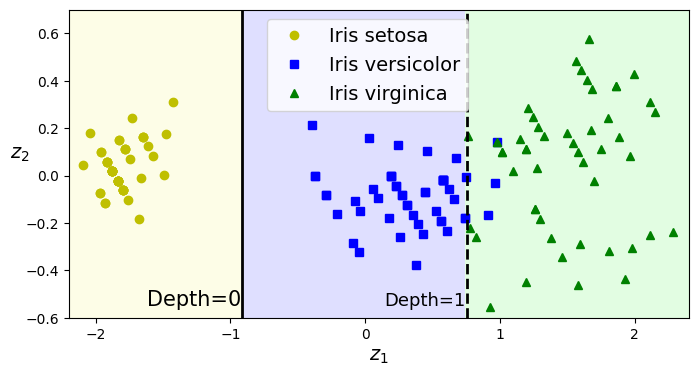

In [30]:
# extra code – this cell generates Figure 5–8

plt.figure(figsize=(8, 4))

axes = [-2.2, 2.4, -0.6, 0.7]
z0s, z1s = np.meshgrid(np.linspace(axes[0], axes[1], 100),
                       np.linspace(axes[2], axes[3], 100))
X_iris_pca_all = np.c_[z0s.ravel(), z1s.ravel()]
y_pred = tree_clf_pca.predict(X_iris_pca_all).reshape(z0s.shape)

plt.contourf(z0s, z1s, y_pred, alpha=0.3, cmap=custom_cmap)
for idx, (name, style) in enumerate(zip(iris.target_names, ("yo", "bs", "g^"))):
    plt.plot(X_iris_rotated[:, 0][y_iris == idx],
             X_iris_rotated[:, 1][y_iris == idx],
             style, label=f"Iris {name}")

plt.xlabel("$z_1$")
plt.ylabel("$z_2$", rotation=0)
th1, th2 = tree_clf_pca.tree_.threshold[[0, 2]]
plt.plot([th1, th1], axes[2:], "k-", linewidth=2)
plt.plot([th2, th2], axes[2:], "k--", linewidth=2)
plt.text(th1 - 0.01, axes[2] + 0.05, "Depth=0",
         horizontalalignment="right", fontsize=15)
plt.text(th2 - 0.01, axes[2] + 0.05, "Depth=1",
         horizontalalignment="right", fontsize=13)
plt.axis(axes)
plt.legend(loc=(0.32, 0.67))

plt.show()

In [37]:
tree_clf_tweaked = DecisionTreeClassifier(max_depth=2, random_state=40)
tree_clf_tweaked.fit(X_iris, y_iris)

DecisionTreeClassifier(max_depth=2, random_state=40)

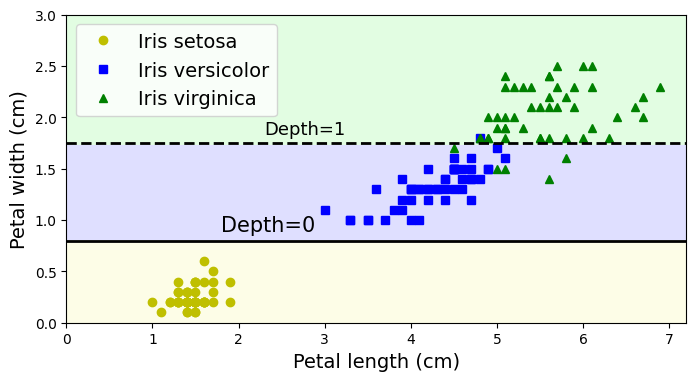

In [38]:
# extra code – this cell generates Figure 5–9

plt.figure(figsize=(8, 4))
y_pred = tree_clf_tweaked.predict(X_iris_all).reshape(lengths.shape)
plt.contourf(lengths, widths, y_pred, alpha=0.3, cmap=custom_cmap)

for idx, (name, style) in enumerate(zip(iris.target_names, ("yo", "bs", "g^"))):
    plt.plot(X_iris[:, 0][y_iris == idx], X_iris[:, 1][y_iris == idx],
             style, label=f"Iris {name}")

th0, th1 = tree_clf_tweaked.tree_.threshold[[0, 2]]
plt.plot([0, 7.2], [th0, th0], "k-", linewidth=2)
plt.plot([0, 7.2], [th1, th1], "k--", linewidth=2)
plt.text(1.8, th0 + 0.05, "Depth=0", verticalalignment="bottom", fontsize=15)
plt.text(2.3, th1 + 0.05, "Depth=1", verticalalignment="bottom", fontsize=13)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.axis([0, 7.2, 0, 3])
plt.legend()

plt.show()

In [39]:
tree = tree_clf.tree_
tree

In [40]:
tree.node_count

5

In [41]:
tree.max_depth

2

In [42]:
tree.max_n_classes

3

In [43]:
tree.n_features

2

In [45]:
tree.n_outputs

1

In [46]:
tree.n_leaves

np.int64(3)

In [47]:
tree.impurity

array([0.66666667, 0.        , 0.5       , 0.16803841, 0.04253308])

In [48]:
tree.children_left[0], tree.children_right[0]

(np.int64(1), np.int64(2))

In [49]:
tree.children_left[3], tree.children_right[3]

(np.int64(-1), np.int64(-1))

In [50]:
is_leaf = (tree.children_left == tree.children_right)
np.arange(tree.node_count)[is_leaf]

array([1, 3, 4])

In [51]:
tree.feature

array([ 0, -2,  1, -2, -2], dtype=int64)

In [52]:
tree.threshold

array([ 2.44999999, -2.        ,  1.75      , -2.        , -2.        ])

In [53]:
tree.value

array([[[0.33333333, 0.33333333, 0.33333333]],

       [[1.        , 0.        , 0.        ]],

       [[0.        , 0.5       , 0.5       ]],

       [[0.        , 0.90740741, 0.09259259]],

       [[0.        , 0.02173913, 0.97826087]]])

In [54]:
tree.n_node_samples

array([150,  50, 100,  54,  46], dtype=int64)

In [55]:
np.all(tree.value.sum(axis=(1, 2)) == tree.n_node_samples)

np.False_

In [56]:
def compute_depth(tree_clf):
    tree = tree_clf.tree_
    depth = np.zeros(tree.node_count)
    stack = [(0, 0)]
    while stack:
        node, node_depth = stack.pop()
        depth[node] = node_depth
        if tree.children_left[node] != tree.children_right[node]:
            stack.append((tree.children_left[node], node_depth + 1))
            stack.append((tree.children_right[node], node_depth + 1))
    return depth

depth = compute_depth(tree_clf)
depth

array([0., 1., 1., 2., 2.])

In [57]:
tree_clf.tree_.feature[(depth == 1) & (~is_leaf)]

array([1], dtype=int64)

In [58]:
tree_clf.tree_.threshold[(depth == 1) & (~is_leaf)]

array([1.75])

Ex #7

In [59]:
from sklearn.datasets import make_moons

dt7_X, dt7_y = make_moons(
    n_samples=10_000,
    noise=0.4,
    random_state=42
)

print("Input shape:", dt7_X.shape)
print("Target shape:", dt7_y.shape)

Input shape: (10000, 2)
Target shape: (10000,)


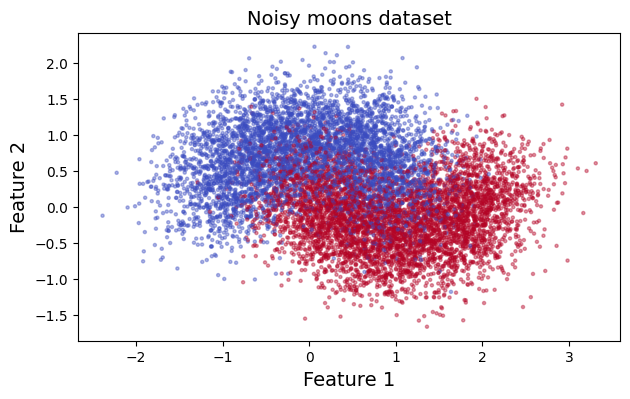

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.scatter(
    dt7_X[:, 0],
    dt7_X[:, 1],
    c=dt7_y,
    cmap="coolwarm",
    s=5,
    alpha=0.4
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Noisy moons dataset")
plt.show()

In [61]:
from sklearn.model_selection import train_test_split

dt7_X_train, dt7_X_test, dt7_y_train, dt7_y_test = (
    train_test_split(
        dt7_X,
        dt7_y,
        test_size=0.2,
        random_state=42
    )
)

print("Training examples:", len(dt7_y_train))
print("Test examples:", len(dt7_y_test))

Training examples: 8000
Test examples: 2000


In [62]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

dt7_param_grid = {
    "max_leaf_nodes": list(range(2, 100)),
    "max_depth": [1, 2, 3, 4, 5, 6],
    "min_samples_split": [2, 3, 4]
}

dt7_grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt7_param_grid,
    scoring="accuracy",
    cv=3,
    refit=True,
    n_jobs=-1
)

In [63]:
dt7_grid_search.fit(dt7_X_train, dt7_y_train)

print("Best parameters:")
print(dt7_grid_search.best_params_)

print(
    f"\nBest mean CV accuracy: "
    f"{dt7_grid_search.best_score_:.2%}"
)

Best parameters:
{'max_depth': 6, 'max_leaf_nodes': 17, 'min_samples_split': 2}

Best mean CV accuracy: 85.41%


In [64]:
dt7_best_tree = dt7_grid_search.best_estimator_

print(dt7_best_tree)
print("Actual tree depth:", dt7_best_tree.get_depth())
print("Number of leaves:", dt7_best_tree.get_n_leaves())

DecisionTreeClassifier(max_depth=6, max_leaf_nodes=17, random_state=42)
Actual tree depth: 6
Number of leaves: 17


In [65]:
from sklearn.metrics import accuracy_score

dt7_test_predictions = dt7_best_tree.predict(dt7_X_test)

dt7_test_accuracy = accuracy_score(
    dt7_y_test,
    dt7_test_predictions
)

print(f"Test accuracy: {dt7_test_accuracy:.2%}")
print(
    "Correct predictions:",
    (dt7_test_predictions == dt7_y_test).sum(),
    "out of",
    len(dt7_y_test)
)

Test accuracy: 85.95%
Correct predictions: 1719 out of 2000


Ex #8

In [66]:
from sklearn.model_selection import ShuffleSplit

dt8_n_trees = 1000
dt8_subset_size = 100

dt8_splitter = ShuffleSplit(
    n_splits=dt8_n_trees,
    train_size=dt8_subset_size,
    random_state=42
)

dt8_subsets = []

for dt8_subset_indices, _ in dt8_splitter.split(dt7_X_train):
    dt8_subsets.append((
        dt7_X_train[dt8_subset_indices],
        dt7_y_train[dt8_subset_indices]
    ))

print("Number of subsets:", len(dt8_subsets))
print("Examples per subset:", len(dt8_subsets[0][1]))

Number of subsets: 1000
Examples per subset: 100


In [67]:
import numpy as np
from sklearn.base import clone
from sklearn.metrics import accuracy_score

dt8_forest = []

dt8_individual_accuracies = []

# Each row will hold one tree's predictions for all test examples.
dt8_predictions = np.empty(
    (dt8_n_trees, len(dt7_X_test)),
    dtype=np.int64
)

for dt8_tree_index, (dt8_X_subset, dt8_y_subset) in enumerate(
    dt8_subsets
):
    dt8_tree = clone(dt7_best_tree)

    dt8_tree.fit(dt8_X_subset, dt8_y_subset)

    dt8_tree_predictions = dt8_tree.predict(dt7_X_test)

    dt8_predictions[dt8_tree_index] = dt8_tree_predictions

    dt8_individual_accuracies.append(
        accuracy_score(dt7_y_test, dt8_tree_predictions)
    )

    dt8_forest.append(dt8_tree)

print("Trained trees:", len(dt8_forest))
print(
    f"Mean individual-tree test accuracy: "
    f"{np.mean(dt8_individual_accuracies):.2%}"
)
print("Prediction matrix shape:", dt8_predictions.shape)

Trained trees: 1000
Mean individual-tree test accuracy: 80.57%
Prediction matrix shape: (1000, 2000)


In [68]:
from scipy.stats import mode

dt8_vote_result = mode(
    dt8_predictions,
    axis=0,
    keepdims=False
)

dt8_majority_predictions = dt8_vote_result.mode

print(
    "Majority predictions shape:",
    dt8_majority_predictions.shape
)

Majority predictions shape: (2000,)


In [69]:
dt8_first_votes = np.bincount(
    dt8_predictions[:, 0],
    minlength=2
)

print("Votes for class 0:", dt8_first_votes[0])
print("Votes for class 1:", dt8_first_votes[1])
print("Majority prediction:", dt8_majority_predictions[0])
print("Actual class:", dt7_y_test[0])

Votes for class 0: 51
Votes for class 1: 949
Majority prediction: 1
Actual class: 1


In [70]:
dt8_forest_accuracy = accuracy_score(
    dt7_y_test,
    dt8_majority_predictions
)

dt8_gain = 100 * (
    dt8_forest_accuracy - dt7_test_accuracy
)

print(f"Original tree accuracy: {dt7_test_accuracy:.2%}")
print(
    f"Mean small-tree accuracy: "
    f"{np.mean(dt8_individual_accuracies):.2%}"
)
print(f"Forest accuracy:         {dt8_forest_accuracy:.2%}")
print(f"Change from original:    {dt8_gain:+.2f} percentage points")

Original tree accuracy: 85.95%
Mean small-tree accuracy: 80.57%
Forest accuracy:         87.30%
Change from original:    +1.35 percentage points
